In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim


In [3]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler



In [4]:
digits = load_digits()

In [5]:
X,y = load_digits(return_X_y=True)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
print(X_train_scaled.shape)

(1437, 64)


In [7]:
print(y.shape)

(1797,)


In [8]:
#converting data to Pytorch tensors

X_train_tensor = torch.tensor(X_train_scaled,dtype = torch.float32)
X_test_tensor = torch.tensor(X_test_scaled,dtype = torch.float32)
y_train_tensor = torch.tensor(y_train,dtype = torch.long)
y_test_tensor = torch.tensor(y_test,dtype = torch.long)

In [9]:
print(X_train_tensor.shape)
print(y_train_tensor.shape)
print(X_test_tensor.dtype)

print(y_test_tensor.dtype)


torch.Size([1437, 64])
torch.Size([1437])
torch.float32
torch.int64


In [10]:
#creating dataset and dataloader

train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
train_loader = DataLoader(train_dataset ,batch_size = 64,shuffle = True)
print("Training Sample", len(train_dataset))
print("Batch per epoch", len(train_loader))

Training Sample 1437
Batch per epoch 23


In [11]:
#buildin neural netwrok
class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(64,128) #each image contain 8*8 pixels
        self.fc2 = nn.Linear(128,64) 
        self.fc3 = nn.Linear(64,10) #final output is digit btw 0-9 so output 10
    def forward(self,x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x
        

In [12]:
#creating model 
model = DigitClassifier()
print(model)

DigitClassifier(
  (fc1): Linear(in_features=64, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)


In [13]:
# train the model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr = 0.0001)
epochs = 50

In [14]:
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for X_batch , y_batch in train_loader:
        optimizer.zero_grad() #clear old gradiend
        outputs = model(X_batch) # forward pass
        loss = criterion(outputs,y_batch)
        loss.backward() #backpropagation 
        optimizer.step() # update model weight
        total_loss += loss.item()
    avg_loss = total_loss/len(train_loader)
    print(f"Epoch[{epoch+1}/{epochs}],Loss:{avg_loss:.4f}")

Epoch[1/50],Loss:2.3133
Epoch[2/50],Loss:2.2659
Epoch[3/50],Loss:2.2214
Epoch[4/50],Loss:2.1695
Epoch[5/50],Loss:2.1113
Epoch[6/50],Loss:2.0444
Epoch[7/50],Loss:1.9656
Epoch[8/50],Loss:1.8770
Epoch[9/50],Loss:1.7804
Epoch[10/50],Loss:1.6707
Epoch[11/50],Loss:1.5528
Epoch[12/50],Loss:1.4315
Epoch[13/50],Loss:1.3078
Epoch[14/50],Loss:1.1967
Epoch[15/50],Loss:1.0874
Epoch[16/50],Loss:0.9841
Epoch[17/50],Loss:0.8942
Epoch[18/50],Loss:0.8105
Epoch[19/50],Loss:0.7334
Epoch[20/50],Loss:0.6705
Epoch[21/50],Loss:0.6112
Epoch[22/50],Loss:0.5662
Epoch[23/50],Loss:0.5237
Epoch[24/50],Loss:0.4847
Epoch[25/50],Loss:0.4485
Epoch[26/50],Loss:0.4169
Epoch[27/50],Loss:0.3885
Epoch[28/50],Loss:0.3654
Epoch[29/50],Loss:0.3435
Epoch[30/50],Loss:0.3220
Epoch[31/50],Loss:0.3054
Epoch[32/50],Loss:0.2892
Epoch[33/50],Loss:0.2722
Epoch[34/50],Loss:0.2584
Epoch[35/50],Loss:0.2484
Epoch[36/50],Loss:0.2345
Epoch[37/50],Loss:0.2271
Epoch[38/50],Loss:0.2135
Epoch[39/50],Loss:0.2066
Epoch[40/50],Loss:0.1962
Epoch[41/

In [15]:
#Evaluating model

model.eval()
with torch.no_grad():
    outputs = model(X_test_tensor)
    predictions = torch.argmax(outputs,dim = 1)
accuracy = (predictions == y_test_tensor).float().mean()
print("Test accuracy: {accuracy.item()*100:2f}%")

Test accuracy: {accuracy.item()*100:.2f}%


In [16]:
accuracy

tensor(0.9694)

<function matplotlib.pyplot.show(close=None, block=None)>

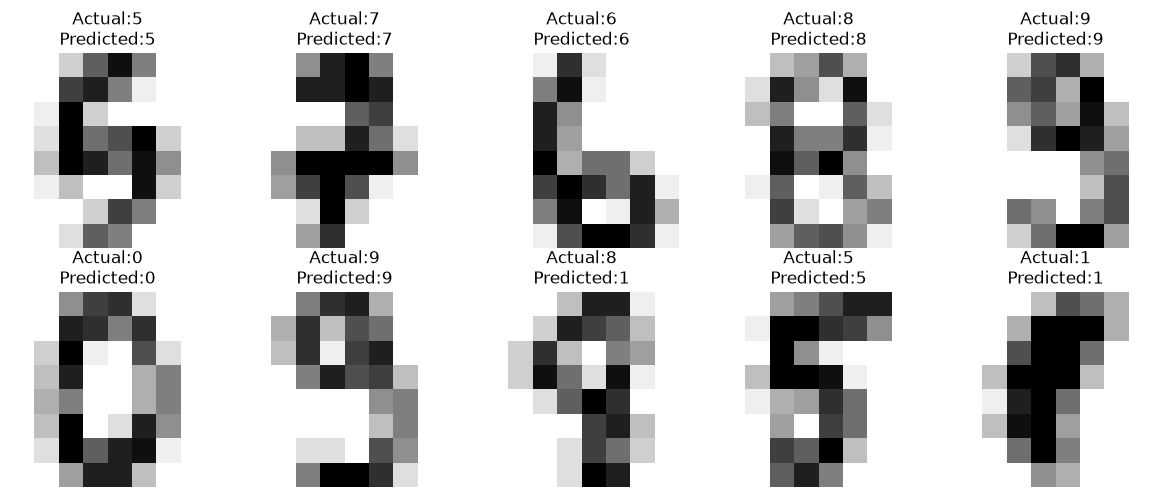

In [17]:
import matplotlib.pyplot as plt
fig,axes = plt.subplots(2,5,figsize = (12,5))
for i , ax in enumerate(axes.flat):
    image = X_test[i].reshape(8,8)
    ax.imshow(image,cmap="gray_r")
    ax.set_title(f"Actual:{y_test[i]}\nPredicted:{predictions[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show

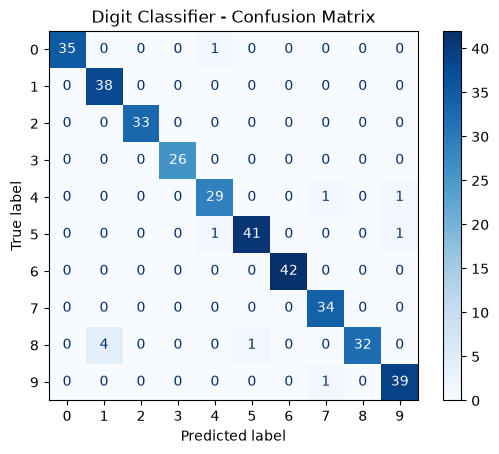

In [18]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test,predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=range(10))
disp.plot(cmap = "Blues",values_format="d")
plt.title("Digit Classifier - Confusion Matrix")
plt.show()

In [19]:
from sklearn.metrics import classification_report,confusion_matrix
print(classification_report(y_test_tensor.numpy(),predictions.numpy()))
print(confusion_matrix(y_test_tensor.numpy(),predictions.numpy()))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.90      1.00      0.95        38
           2       1.00      1.00      1.00        33
           3       1.00      1.00      1.00        26
           4       0.94      0.94      0.94        31
           5       0.98      0.95      0.96        43
           6       1.00      1.00      1.00        42
           7       0.94      1.00      0.97        34
           8       1.00      0.86      0.93        37
           9       0.95      0.97      0.96        40

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360

[[35  0  0  0  1  0  0  0  0  0]
 [ 0 38  0  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  0 26  0  0  0  0  0  0]
 [ 0  0  0  0 29  0  0  1  0  1]
 [ 0  0  0  0  1 41  0  0  0  1]
 [ 0  0  0  0  0  0 42  0  0  0]
 [ 0  0  0

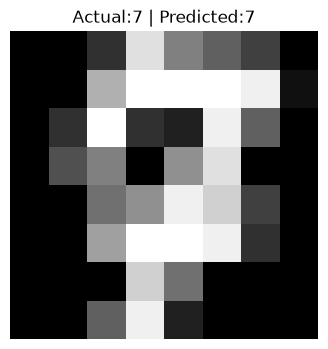

In [21]:
#single image from the dataset
import matplotlib.pyplot as plt
import torch 
#selec one image from the test dataset
index = 25
sample = X_test_tensor[index].unsqueeze(0)
actual_digit = y_test_tensor[index].item()
model.eval()
with torch.no_grad():
    output = model(sample)
    predicted_digit = torch.argmax(output,dim = 1).item()
    #display the digit
plt.figure(figsize = (4,4))
plt.imshow(X_test[index].reshape(8,8),cmap = "gray")
plt.title(f"Actual:{actual_digit} | Predicted:{predicted_digit}")
plt.axis("off")
plt.show()


In [2]:
#CNN
#loading datasets
from torchvision import datasets,transforms

In [4]:
transform = transforms.ToTensor() #converts the image to pytorch sensor and scales the pixels to 0-1

In [9]:
train_data = datasets.MNIST(
    root="./data",
    train =True, 
    download = True,
    transform=transform
) #train true loads 60000 training images,false loads 10000 test images
test_data = datasets.MNIST(
    root="./data",
    train =False, 
    download = True,
    transform=transform
)


In [10]:
print("Training Sample", len(train_data))
print("Testing Sample", len(test_data))

Training Sample 60000
Testing Sample 10000


Image shape torch.Size([1, 28, 28])
Actual Digit: 5


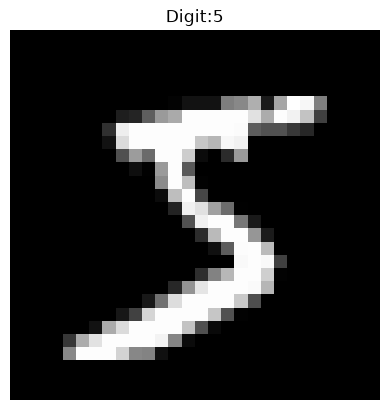

In [12]:
#inspecting one image
import matplotlib.pyplot as plt
image,label = train_data[0]
print("Image shape",image.shape) #shape (batchsize,channels,height,width) #(1 grayscale chnnl,imghght,imgwdth)
print("Actual Digit:",label)
plt.imshow(image.squeeze(),cmap = "gray")#squeeze used for displaying img
plt.title(f"Digit:{label}")
plt.axis("off")
plt.show()

In [14]:
#creatin a dataloader
from torch.utils.data import DataLoader
train_loader_cnn = DataLoader(
    train_data,
    batch_size = 64,
    shuffle = True
)
test_loader_cnn = DataLoader(
    test_data,
    batch_size = 64,
    shuffle = False
)
images,labels = next(iter(train_loader_cnn)) #iter creates iterator that can retrieve batches from dataloader
                                             #next receives next batch from the iterator
print("Batch image shape",images.shape)
print("Batch label shape",labels.shape)



Batch image shape torch.Size([64, 1, 28, 28])
Batch label shape torch.Size([64])


In [20]:
#creating convolutional layer
import torch 
import torch.nn as nn
sample_batch = torch.randn(32,1,28,28)
conv_layer = nn.Conv2d(
    in_channels = 1,
    out_channels = 16,
    kernel_size = 3
)
conv_output = conv_layer(sample_batch)


In [21]:
print("Input shape:",sample_batch.shape)
print("Output shape:",conv_output.shape) #1->>16 one input channel becomes 16 fmaps
                                         #28->>26 3*3 filter w default stride 1 so 28-3+1

Input shape: torch.Size([32, 1, 28, 28])
Output shape: torch.Size([32, 16, 26, 26])


In [24]:
#applying relu cz fmaps can contain positive and neg vals
relu_output  = torch.relu(conv_output)
print(relu_output.shape) #changes the value not the shape so the dimensions remain the same

torch.Size([32, 16, 26, 26])


In [26]:
#after convolution and ReLU we apply Max pooling to reduce the spatial size of fmaps while
#retaining the strong features
pool = nn.MaxPool2d(kernel_size =2,stride =2)
pool_output = pool(relu_output)
print("Before pooling:",relu_output.shape)
print("After pooling:",pool_output.shape) #use of pool is to reduce the spatial dim while retaining strong activatons
                                          #(imgs in batch,feature per img,dim)
                                         

Before pooling: torch.Size([32, 16, 26, 26])
After pooling: torch.Size([32, 16, 13, 13])


In [28]:
#flattening 
flatten = nn.Flatten()
flat_output = flatten(pool_output)
print("Before flattening:",pool_output.shape)
print("After flattening:",flat_output.shape) #converts into 1D vector 16*13*13

#32 images is represented by 2704 features

Before flattening: torch.Size([32, 16, 13, 13])
After flattening: torch.Size([32, 2704])


In [30]:
 #implementing the fully connected layers
fc1 = nn.Linear(2704,128)
fc2 = nn.Linear(128,10)
hidden = torch.relu(fc1(flat_output))
scores = fc2(hidden) #final output layer

In [31]:
print("Flattened shape:",flat_output.shape)
print("Hidden Layer shape:",hidden.shape)
print("Output scores shape:",scores.shape)

Flattened shape: torch.Size([32, 2704])
Hidden Layer shape: torch.Size([32, 128])
Output scores shape: torch.Size([32, 10])


In [40]:
#final output layer

import torch 
import torch.nn as nn
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(
    in_channels = 1,
    out_channels = 16,
    kernel_size = 3
)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size =2,
                                 stride =2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(2704,128)
        self.fc2 = nn.Linear(128,10)
    def forward(self,x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x
        #forward defines the flow of data flows in these layers 
model = CNN()
print(model)
        
        
  

CNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=2704, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
# Testin the model before trainin 
sample_images,sample_labels = next(iter(train_loader_cnn))
with torch.no_grad():
    output = model(sample_images)
print("Input shape:",sample_images.shape)
print("Output shape:",output.shape)
print("First images scores:",output[0])
print("Precited Digit:",output[0].argmax().item())
print("Actual Digit:",sample_labels[0].item())



In [52]:
#preparing for the training 
criterion = nn.CrossEntropyLoss() #loss function
optimizer = torch.optim.Adam(
    model.parameters(),
    lr = 0.001
)
print("Loss Function:",criterion)
print("Optimizer:",optimizer)


Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [56]:
#training loop
epochs = 3
for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for images,labels in train_loader_cnn:
        optimizer.zero_grad() #clear gradients from the previous batch
        outputs = model(images)#forward pass:get predcitions
        loss = criterion(outputs,labels)#calculate loss
        loss.backward()#backpropagation calculate gradients
        optimizer.step() #update model parameters 
        total_loss +=loss.item()
        predictions = outputs.argmax(dim=1)
        correct+=(predictions == labels).sum().item()
        total+=labels.size(0)
    avg_loss = total_loss/len(train_loader_cnn)
    accuracy = 100*correct/total
    print(f"Epoch [{epoch+1}/{epochs}]"
         f"Loss:{avg_loss:.4f}"
         f"Accuracy:{accuracy:.2f}%"
         )

Epoch [1/3]Loss:0.0059Accuracy:99.81%
Epoch [2/3]Loss:0.0049Accuracy:99.87%
Epoch [3/3]Loss:0.0038Accuracy:99.89%


In [57]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images,labels in test_loader_cnn:
        outputs = model(images)
        predcitions = outputs.argmax(dim=1)
        correct+=(predcitions == labels).sum().item()
        total +=labels.size(0)
test_accuracy = 100*correct/total
print(f"Test Accuracy:{test_accuracy:.2f}%")
print(f"Correct predictions:{correct}/{total}")

Test Accuracy:98.61%
Correct predictions:9861/10000


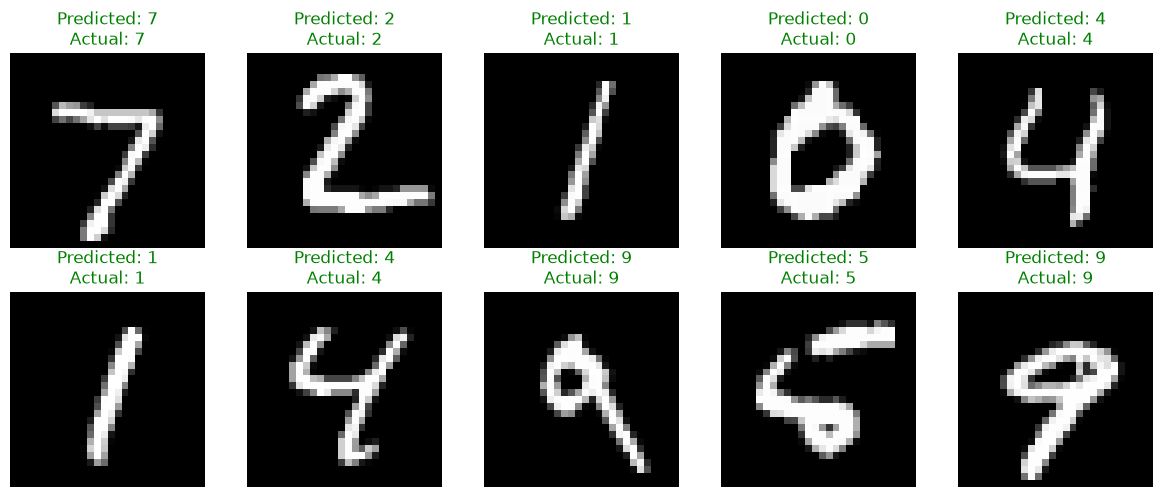

In [58]:

import matplotlib.pyplot as plt

# Get one batch of test images
images, labels = next(iter(test_loader_cnn))

# Make predictions without calculating gradients
model.eval()
with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

# Display the first 10 images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    predicted = predictions[i].item()
    actual = labels[i].item()

    ax.set_title(
        f"Predicted: {predicted}\nActual: {actual}",
        color="green" if predicted == actual else "red"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()
